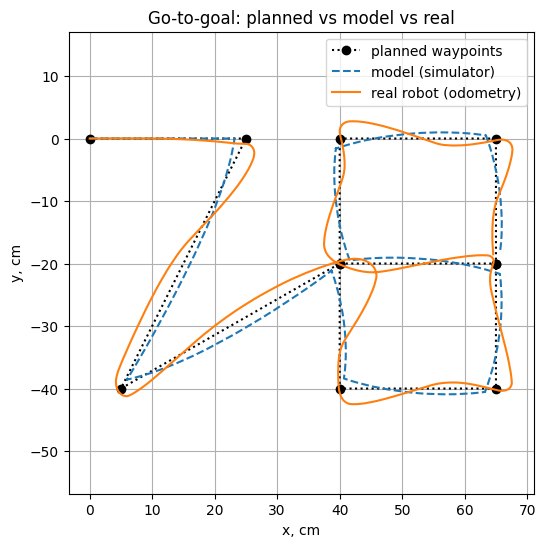

Waypoint 0 (np.int64(0), np.int64(0)): sim   0.0 cm | real   0.0 cm
Waypoint 1 (np.int64(25), np.int64(0)): sim   1.8 cm | real   0.8 cm
Waypoint 2 (np.int64(5), np.int64(-40)): sim   1.7 cm | real   0.6 cm
Waypoint 3 (np.int64(40), np.int64(-20)): sim   1.7 cm | real   0.2 cm
Waypoint 4 (np.int64(40), np.int64(-40)): sim   1.7 cm | real   0.2 cm
Waypoint 5 (np.int64(65), np.int64(-40)): sim   1.5 cm | real   0.3 cm
Waypoint 6 (np.int64(65), np.int64(-20)): sim   1.4 cm | real   0.4 cm
Waypoint 7 (np.int64(40), np.int64(-20)): sim   1.7 cm | real   0.2 cm
Waypoint 8 (np.int64(40), np.int64(0)): sim   1.3 cm | real   0.2 cm
Waypoint 9 (np.int64(65), np.int64(0)): sim   1.3 cm | real   0.3 cm
Waypoint 10 (np.int64(65), np.int64(-20)): sim   1.4 cm | real   0.4 cm
Run time: sim 27.1 s | real 22.0 s


In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

# Planned waypoints: copy them from your TRIK program
wp = np.array([[0, 0],                                  # start = top-left of "7"
               [25, 0], [5, -40],                       # digit 7
               [40, -20],                               # gap to the middle of "8"
               [40, -40], [65, -40], [65, -20],         # digit 8: lower loop
               [40, -20], [40, 0], [65, 0], [65, -20]])

x_s, y_s, t_s = np.loadtxt('gotogol_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('gotogol_data_real.txt', delimiter=',', unpack=True)

# 1. Planned path vs simulated vs real
plt.figure(figsize=(6, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

In [2]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s, wp)
miss_r = waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i} {tuple(wp[i])}: sim {ms:5.1f} cm | real {mr:5.1f} cm')


Waypoint 0 (np.int64(0), np.int64(0)): sim   0.0 cm | real   0.0 cm
Waypoint 1 (np.int64(25), np.int64(0)): sim   1.8 cm | real   0.8 cm
Waypoint 2 (np.int64(5), np.int64(-40)): sim   1.7 cm | real   0.6 cm
Waypoint 3 (np.int64(40), np.int64(-20)): sim   1.7 cm | real   0.2 cm
Waypoint 4 (np.int64(40), np.int64(-40)): sim   1.7 cm | real   0.2 cm
Waypoint 5 (np.int64(65), np.int64(-40)): sim   1.5 cm | real   0.3 cm
Waypoint 6 (np.int64(65), np.int64(-20)): sim   1.4 cm | real   0.4 cm
Waypoint 7 (np.int64(40), np.int64(-20)): sim   1.7 cm | real   0.2 cm
Waypoint 8 (np.int64(40), np.int64(0)): sim   1.3 cm | real   0.2 cm
Waypoint 9 (np.int64(65), np.int64(0)): sim   1.3 cm | real   0.3 cm
Waypoint 10 (np.int64(65), np.int64(-20)): sim   1.4 cm | real   0.4 cm


In [3]:
# 3. Run time
print(f'Run time: sim {(t_s[-1]-t_s[0])/1000:.1f} s | real {(t_r[-1]-t_r[0])/1000:.1f} s')

Run time: sim 27.1 s | real 22.0 s
